In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

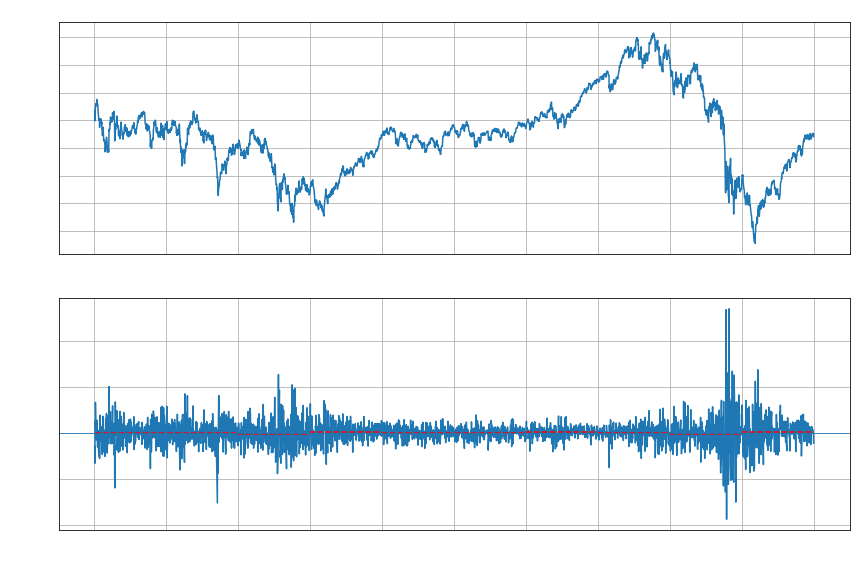

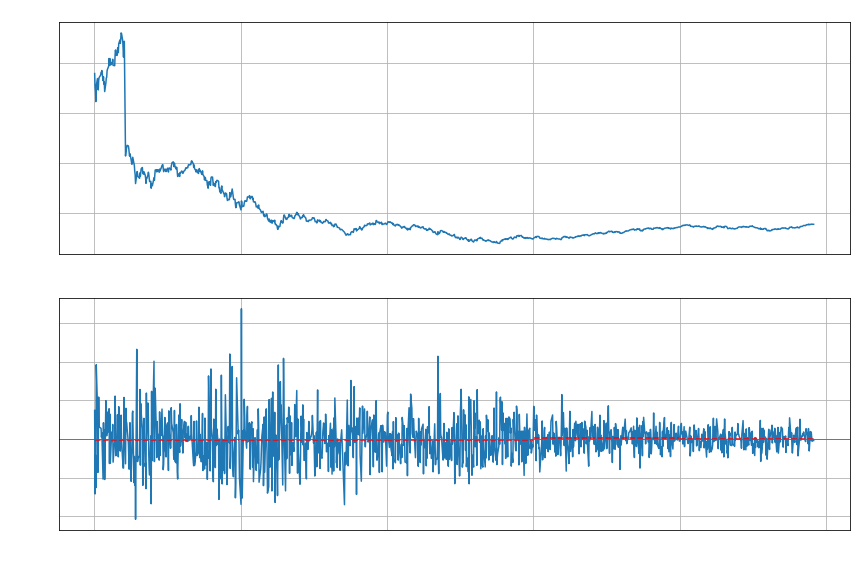

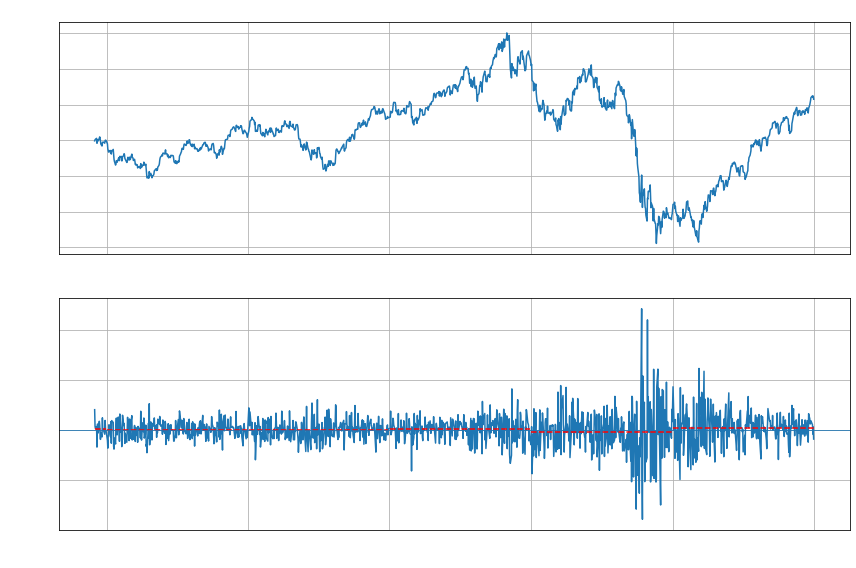

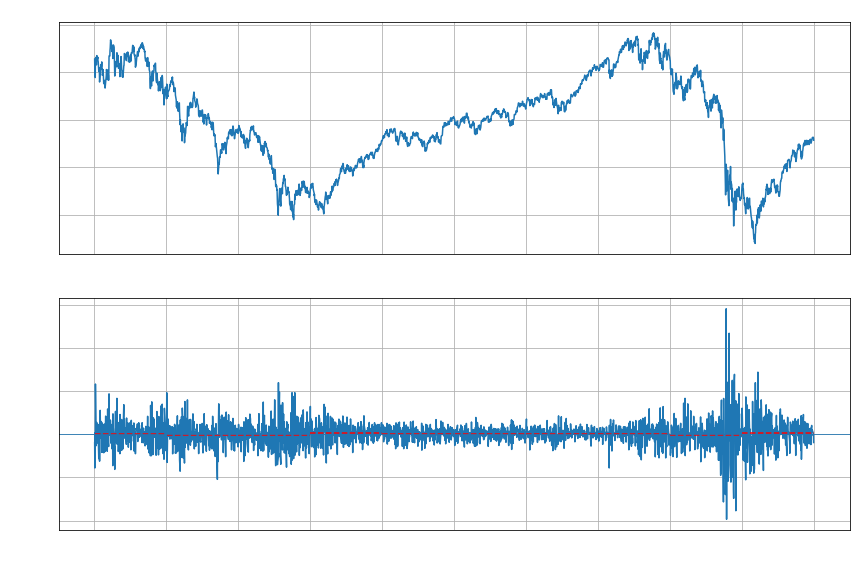

In [3]:
df = pd.read_csv('29379708.csv', usecols=['date', 'TICKER', 'PRC', 'RET'])
result = df.to_dict(orient='records')

df = pd.DataFrame(result)

# Convert dates from strings to datetime objects
df['date'] = pd.to_datetime(df['date'])

# Sort observations chronologically
df = df.sort_values(['TICKER', 'date'])
for ticker, data in df.groupby('TICKER'):
  data = np.log(1 + np.array(data['RET']))

mean_returns = df.groupby([df['date'].dt.year, 'TICKER'])['RET'].mean()

for ticker, data in df.groupby('TICKER'):

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # Plot price
    axes[0].plot(data['date'], data['PRC'])
    axes[0].set_title(f'{ticker} Price Over Time', color='white')
    axes[0].set_ylabel('Price ($)', color='white')
    axes[0].set_xlabel('Date',color='white')
    axes[0].tick_params(axis='x', colors='white')
    axes[0].tick_params(axis='y', colors='white') 
    axes[1].tick_params(axis='x', colors='white')
    axes[1].tick_params(axis='y', colors='white') 
    axes[0].grid(True)

    # Plot returns
    axes[1].plot(data['date'], data['RET'])
    for year, group in df.groupby(data['date'].dt.year):
        mean_return = group['RET'].mean()

        axes[1].hlines(
            y=mean_return,
            xmin=group['date'].min(),
            xmax=group['date'].max(),
            colors='red',
            linestyles='dashed',
            label=f'{year} mean'
        )
    axes[1].set_title(f'{ticker} Daily Returns', color='white')
    axes[1].set_ylabel('Return', color='white')
    axes[1].set_xlabel('Date',color='white')
    axes[1].axhline(0, linewidth=0.8)
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

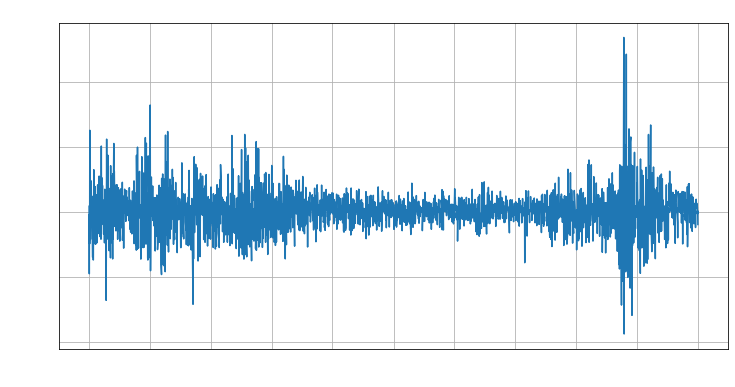

In [4]:
# sum_df = df.groupby(['date']).agg({'PRC': 'sum', 'RET': 'sum'})
sum_df = df.groupby('date').agg({'RET': lambda x: x.sum() / 3})



plt.figure(figsize=(12, 6))
plt.plot(sum_df.index, sum_df['RET'])
plt.title('Equal-Weighted Portfolio Returns Over Time', color='white')
plt.xlabel('Date', color='white')
plt.ylabel('Portfolio Return', color='white')
plt.tick_params(axis='x', colors='white')
plt.tick_params(axis='y', colors='white')
plt.grid(True)
plt.show()

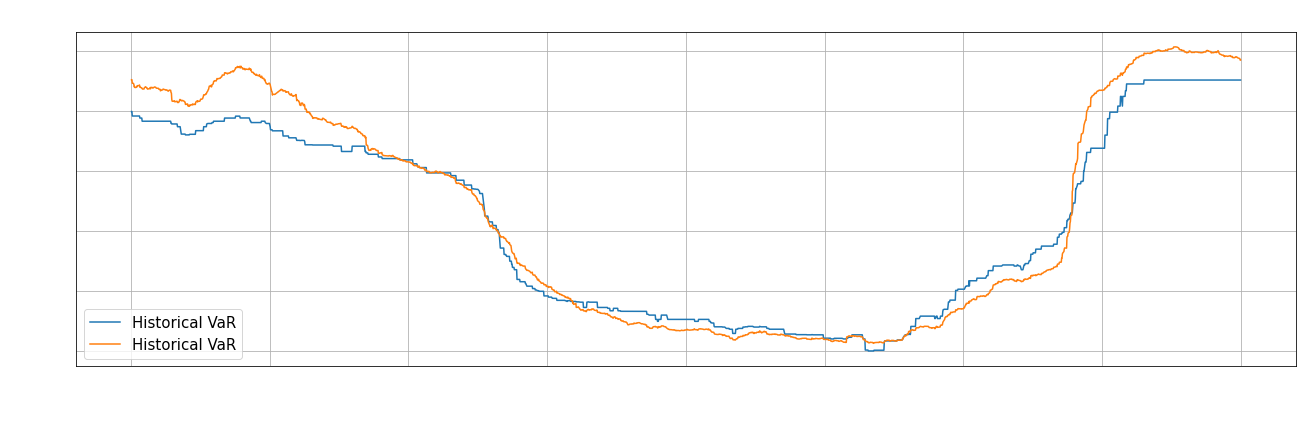

110 112


In [6]:
pre = np.array(sum_df.loc['2000':'2010', 'RET'].dropna())
full = sum_df.loc['2000':'2010', 'RET'].dropna()
quantiles = []
quantiles_param = []
for i in range(0,len(pre)-499):
    list = []
    for j in range(i, i+500):
        list.append(pre[j])
    mean = np.array(list).mean()
    std = np.array(list).std(ddof=1)
    x = np.linspace(mean - 4*std, mean + 4*std, 1000)
    p = norm.ppf(0.05, loc=mean, scale=std)
    quantiles_param.append(-p)
    quantiles.append(np.quantile(list,0.05))
quantiles = -np.array(quantiles)
quantiles_param = np.array(quantiles_param)

dates = sum_df.loc['2000':'2010', 'RET'].dropna().index
quantile_dates = dates[500:]
plt.figure(figsize=(18,6))
plt.plot(quantile_dates, quantiles[:-1], label='Historical VaR')
plt.plot(quantile_dates, quantiles_param[:-1], label='Historical VaR')
plt.xlabel('Date', color='white', fontsize=15)
plt.ylabel('95% One-Day VaR', color='white', fontsize=15)
plt.title('Rolling 500-Day Historical vs Parametric VaR',color='white',fontsize=25)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.tick_params(axis='x', colors='white', labelsize=15)
plt.tick_params(axis='y', colors='white', labelsize=15)  
plt.legend(fontsize=15)
plt.show()

hist_breaches = 0
param_breaches = 0
for i in range(len(quantiles)-1):
    if full.iloc[i + 500] < -quantiles[i]:
        hist_breaches += 1
    if full.iloc[i+500] < -quantiles_param[i]:
        param_breaches += 1
print(hist_breaches, param_breaches)